# Figs. S5 and S6 — Pairwise combination-treatment landscapes at $T = 15$ and $T = 30$ days
The five payoff pairs not shown in Fig. 4. In each composite the upper map is tumor reduction $R_N(T)$ and the lower map
leader suppression $S_L(T) = 1 - x(T)$ (%). The red square marks the dose pair with the largest
$J = \tfrac12(R_N/100 + S_L)$ among these five pairs in each regime.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

In [2]:
doses = np.linspace(0, 1, 11)
D1, D2 = np.meshgrid(doses, doses)           # [dose of 2nd target (y), dose of 1st target (x)]
pairs = [("alpha", "beta"), ("alpha", "gamma"), ("alpha", "delta"), ("beta", "gamma"), ("gamma", "delta")]
sym = {"alpha": r"$R_x\alpha$", "beta": r"$R_x\beta$", "gamma": r"$R_x\gamma$", "delta": r"$R_x\delta$"}

def landscapes(T):
    out = {}
    for name, (b, g) in REGIMES.items():
        res = [treatment_outcome(b, g, {p: D1, q: D2}, T=T) for p, q in pairs]
        k = int(np.argmax([r[2].max() for r in res]))
        best = (k, np.unravel_index(np.argmax(res[k][2]), res[k][2].shape))
        out[name] = (res, best)
        iy, ix = best[1]
        print(f"T={T:.0f} {name:20s} best pair {pairs[k]} at ({doses[ix]:.1f}, {doses[iy]:.1f}), J = {res[k][2][iy, ix]:.3f}")
    return out

def plot(T, fname):
    out = landscapes(T)
    fig = plt.figure(figsize=(15, 17))
    gs = fig.add_gridspec(4, 5, wspace=0.45, hspace=0.3)
    for row, name in enumerate(REGIME_ORDER):
        res, (kbest, ij) = out[name]
        for col, (p, q) in enumerate(pairs):
            axs, im = composite_heatmap(fig, gs[row, col], res[col][0], res[col][1],
                                        ij if col == kbest else None, xlabel=sym[p], ylabel=sym[q], doses=doses)
            if col == 0:
                axs[0].text(-0.75, 1.08, "ABCD"[row], transform=axs[0].transAxes, fontsize=18, fontweight="bold")
                axs[0].text(-0.55, 1.08, name, transform=axs[0].transAxes, fontsize=12, fontweight="bold")
    cax = fig.add_axes([0.25, 0.93, 0.5, 0.01])
    cb = fig.colorbar(im, cax=cax, orientation="horizontal")
    cb.set_label(f"Tumor reduction (%) [upper] / Leader suppression (%) [lower],  T = {T:.0f} days")
    cax.xaxis.set_label_position("top")
    save(fig, fname)
    plt.show()

T=15 Snowdrift            best pair ('beta', 'gamma') at (0.9, 1.0), J = 0.981


T=15 Harmony              best pair ('beta', 'gamma') at (0.8, 1.0), J = 0.829


T=15 Coordination         best pair ('alpha', 'delta') at (1.0, 0.4), J = 0.931


T=15 Prisoner's Dilemma   best pair ('alpha', 'delta') at (1.0, 0.5), J = 0.966


Saved ../figures/FigS5_pairwise_combinations_T15.png/.pdf


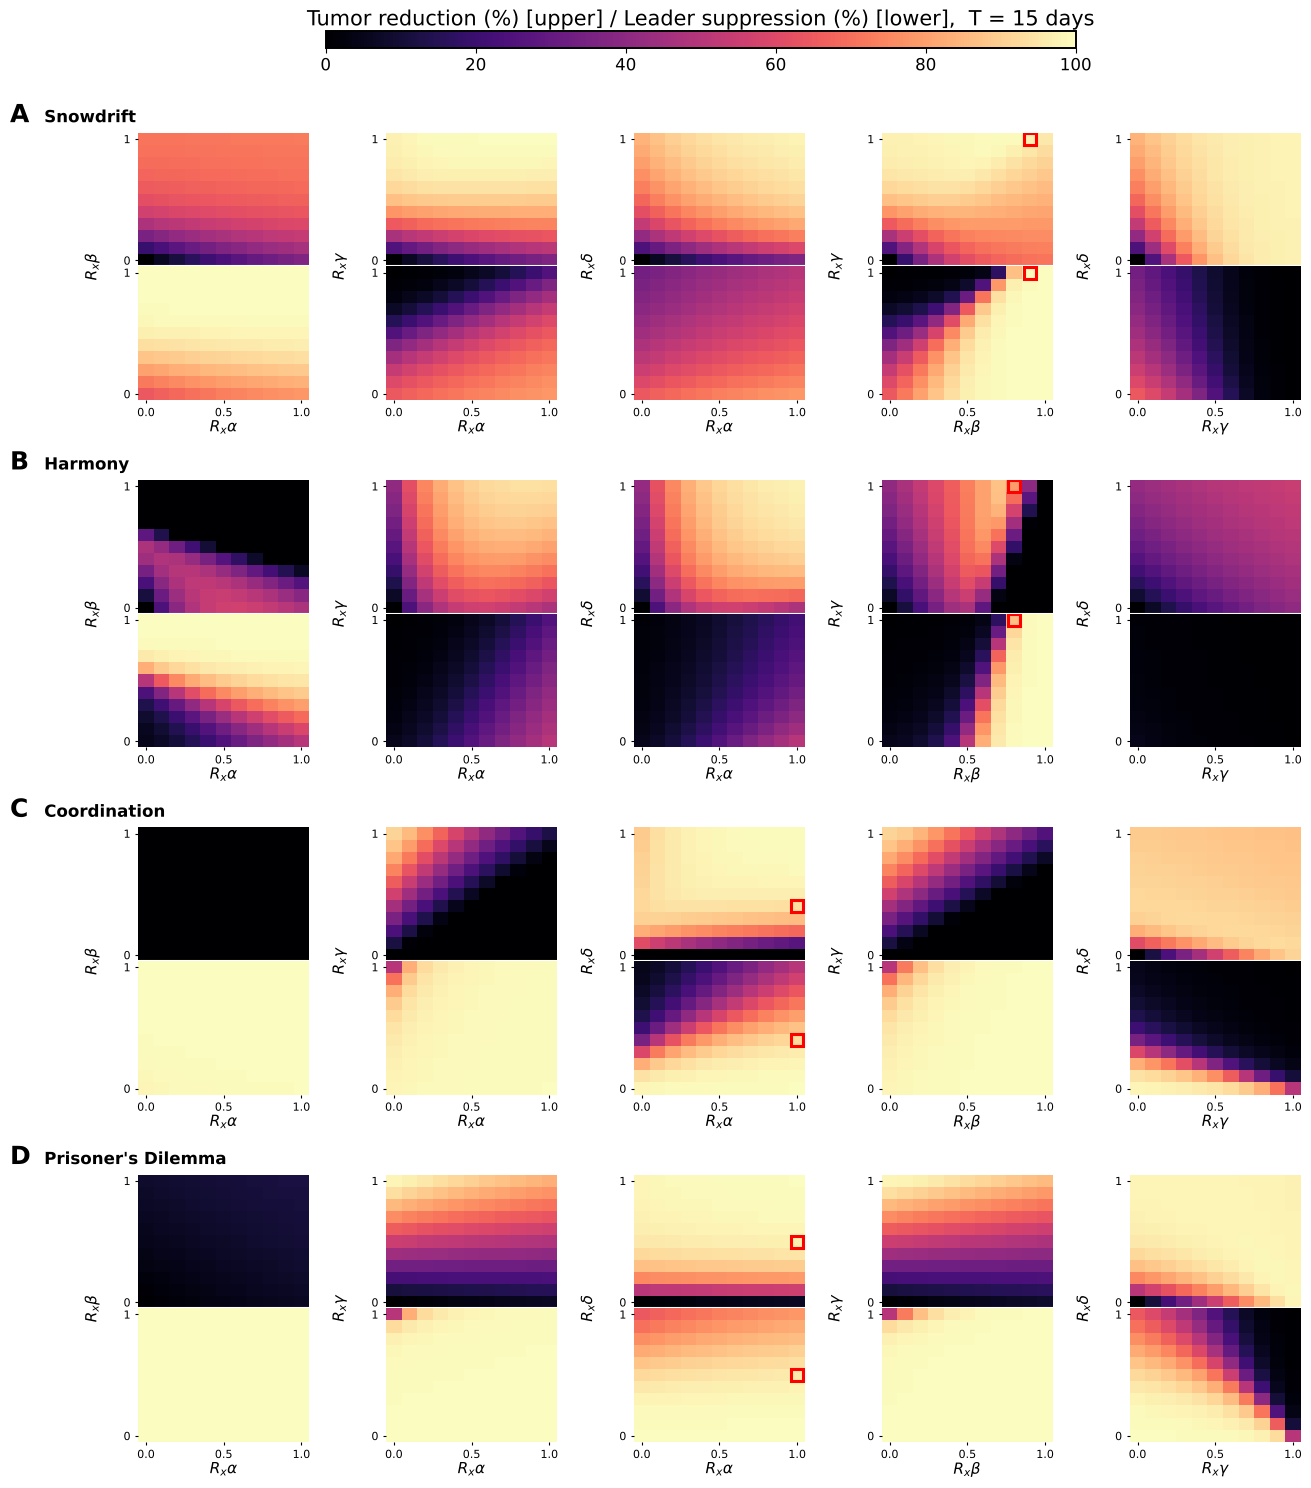

In [3]:
plot(15.0, "FigS5_pairwise_combinations_T15")

T=30 Snowdrift            best pair ('alpha', 'gamma') at (1.0, 0.9), J = 0.629


T=30 Harmony              best pair ('beta', 'gamma') at (0.7, 0.8), J = 0.666


T=30 Coordination         best pair ('alpha', 'delta') at (1.0, 0.5), J = 0.973


T=30 Prisoner's Dilemma   best pair ('alpha', 'delta') at (1.0, 0.6), J = 0.967


Saved ../figures/FigS6_pairwise_combinations_T30.png/.pdf


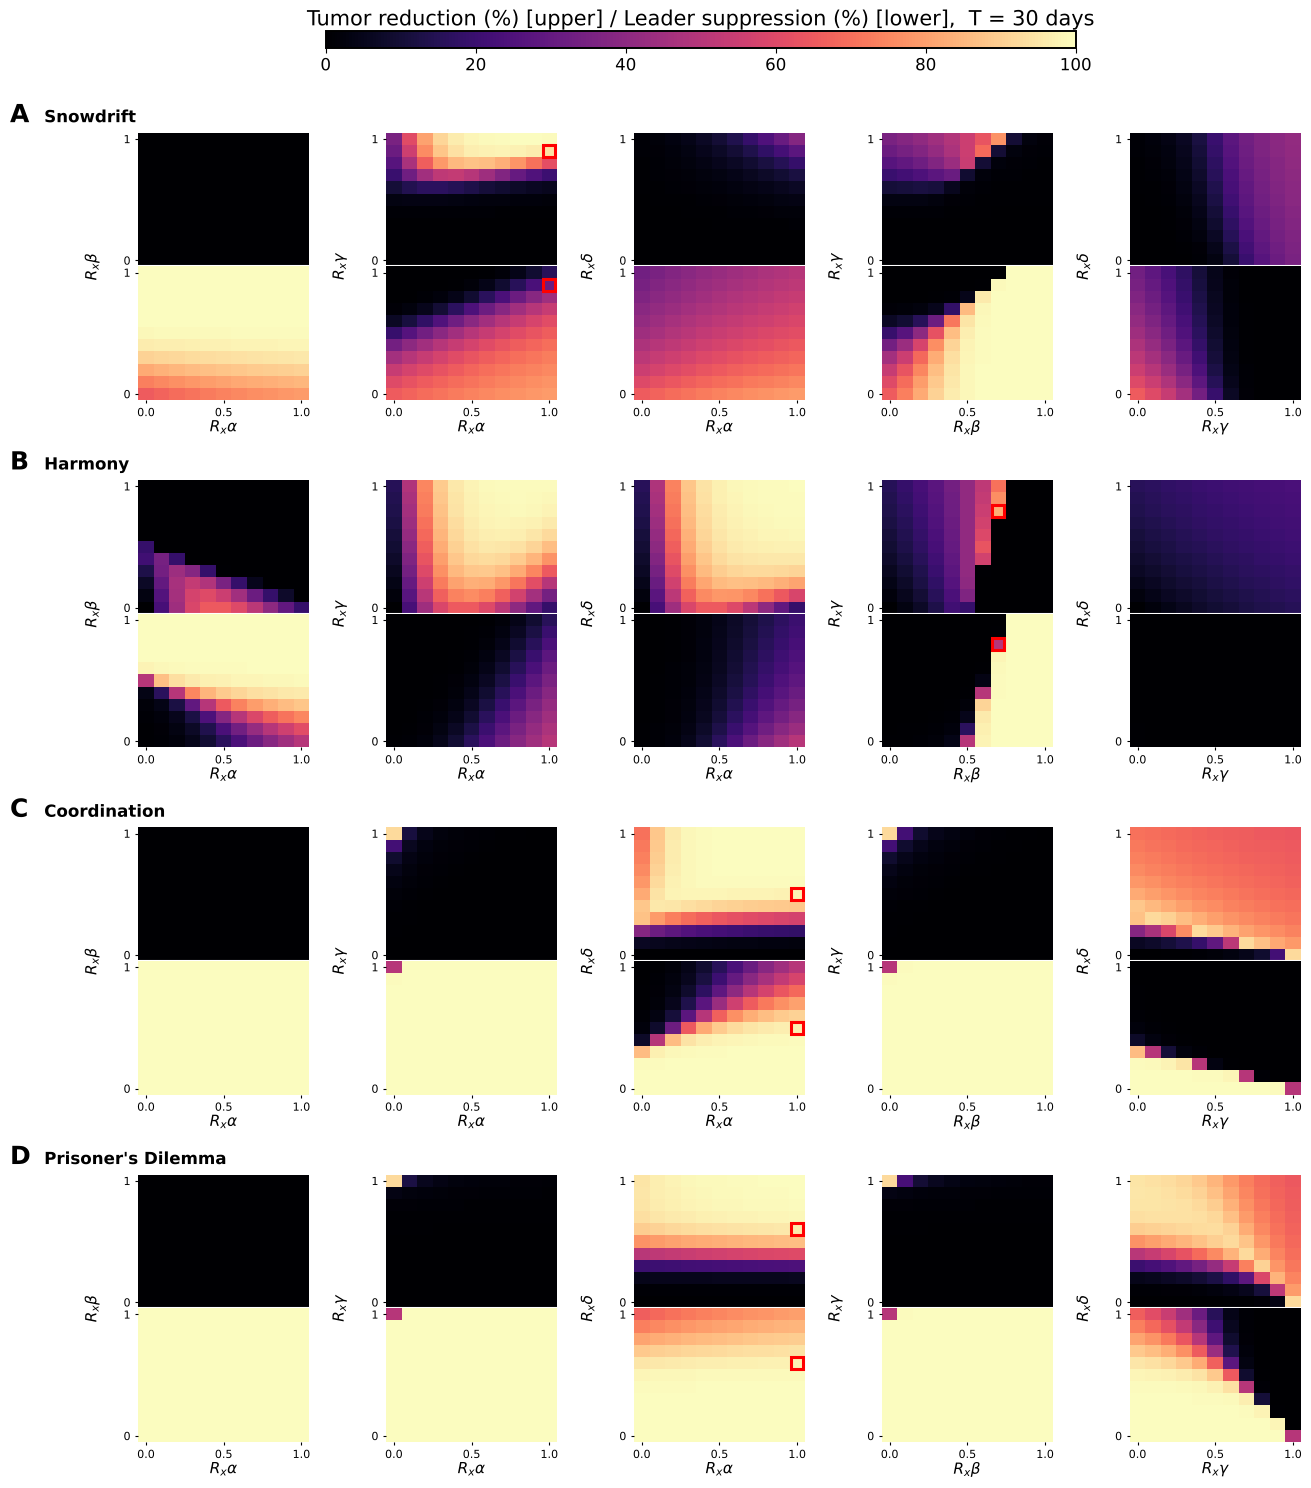

In [4]:
plot(30.0, "FigS6_pairwise_combinations_T30")